Cell-1: Imports

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import mstats
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')
print("All libraries imported successfully!")

All libraries imported successfully!


Cell-2: Load and Inspect Data

In [9]:
df = pd.read_csv('heart_disease_cleveland.csv')
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nData types and null counts:")
df.info()
print("\nBasic statistics:")
display(df.describe())

Shape: (297, 14)

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0



Data types and null counts:
<class 'pandas.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    int64  
 1   sex       297 non-null    int64  
 2   cp        297 non-null    int64  
 3   trestbps  297 non-null    int64  
 4   chol      297 non-null    int64  
 5   fbs       297 non-null    int64  
 6   restecg   297 non-null    int64  
 7   thalach   297 non-null    int64  
 8   exang     297 non-null    int64  
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    int64  
 11  ca        297 non-null    int64  
 12  thal      297 non-null    int64  
 13  target    297 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.6 KB

Basic statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,0.676768,2.158249,131.693603,247.350168,0.144781,0.996633,149.599327,0.326599,1.055556,0.602694,0.676768,0.835017,0.461279
std,9.049736,0.468500,0.964859,17.762806,51.997583,0.352474,0.994914,22.941562,0.469761,1.166123,0.618187,0.938965,0.956690,0.499340
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,2.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,56.000000,1.000000,2.000000,130.000000,243.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,0.000000,0.000000
75%,61.000000,1.000000,3.000000,140.000000,276.000000,0.000000,2.000000,166.000000,1.000000,1.600000,1.000000,1.000000,2.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,3.000000,2.000000,1.000000


Cell-3: Missing Values

In [10]:
print("Missing values before treatment:")
print(df.isnull().sum())

df.replace('?', np.nan, inplace=True)
df['ca'] = pd.to_numeric(df['ca'], errors='coerce')
df['thal'] = pd.to_numeric(df['thal'], errors='coerce')
df['ca'].fillna(df['ca'].mode()[0], inplace=True)
df['thal'].fillna(df['thal'].mode()[0], inplace=True)

print("\nMissing values after treatment:")
print(df.isnull().sum())

Missing values before treatment:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Missing values after treatment:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


Cell-4: Outlier Treatment and Encoding

In [11]:
# Winsorize outlier columns
for col in ['chol', 'trestbps', 'oldpeak']:
    df[col] = mstats.winsorize(df[col], limits=[0.05, 0.05])

# Target variable
df['target'] = (df['target'] > 0).astype(int)

print("Class distribution:")
print(df['target'].value_counts())
print("\nDataset shape after cleaning:", df.shape)

Class distribution:
target
0    160
1    137
Name: count, dtype: int64

Dataset shape after cleaning: (297, 14)


Cell 5 — Scaling and Train/Val/Test Split:

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = df.drop('target', axis=1)
y = df['target']

# Normalize numerical features
scaler = StandardScaler()
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
X[num_cols] = scaler.fit_transform(X[num_cols])

# Split: 70% train, 15% val, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Train: (207, 13), Val: (45, 13), Test: (45, 13)


Cell 6 — Visualization 1: Age Histogram

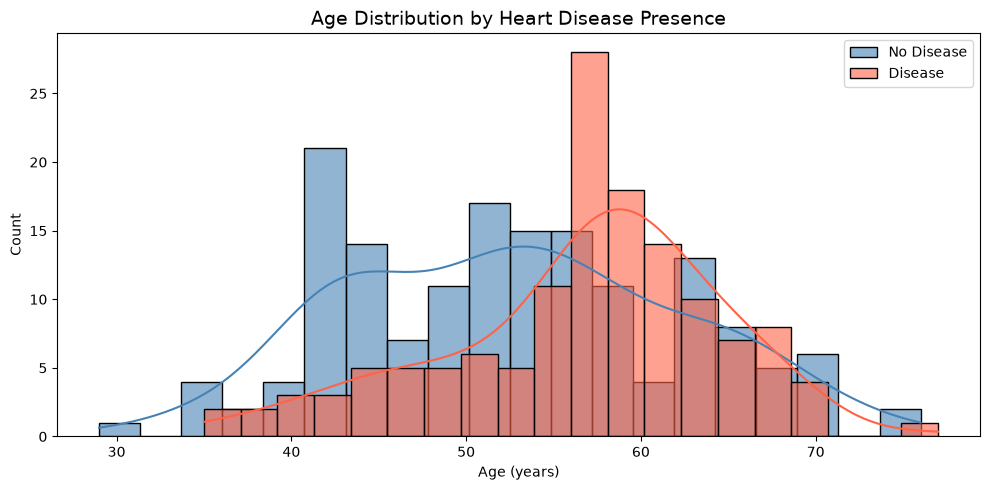

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
for target, label, color in [(0, 'No Disease', 'steelblue'), (1, 'Disease', 'tomato')]:
    subset = df[df['target'] == target]
    sns.histplot(subset['age'], bins=20, kde=True, label=label, color=color, alpha=0.6, ax=ax)
ax.set_title('Age Distribution by Heart Disease Presence', fontsize=14)
ax.set_xlabel('Age (years)')
ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.savefig('viz1_age_distribution.png', dpi=150)
plt.show()

Cell 7 — Visualization 2: Correlation Heatmap

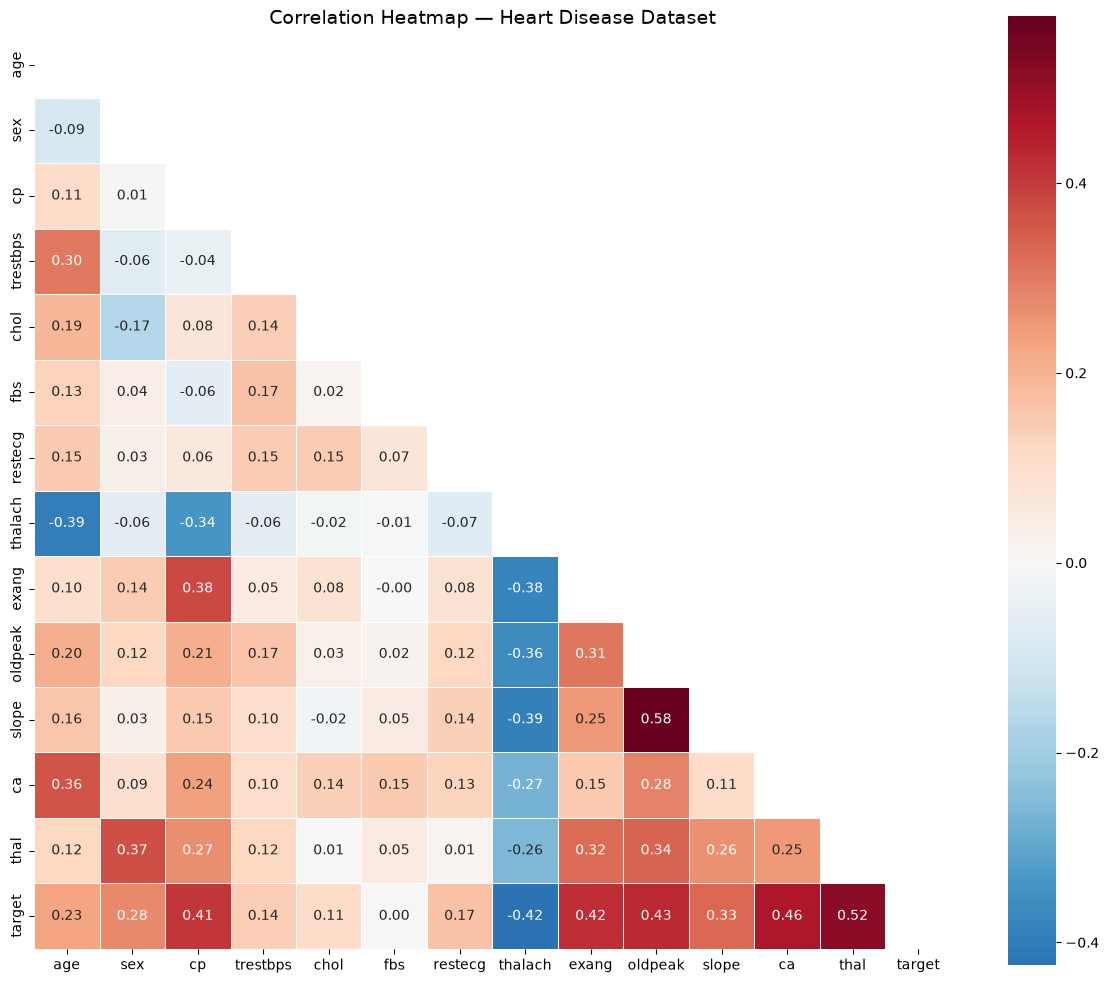

In [14]:
plt.figure(figsize=(12, 10))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, linewidths=0.5, square=True)
plt.title('Correlation Heatmap — Heart Disease Dataset', fontsize=14)
plt.tight_layout()
plt.savefig('viz2_correlation_heatmap.png', dpi=150)
plt.show()

Cell 8 — Visualization 3: Boxplots

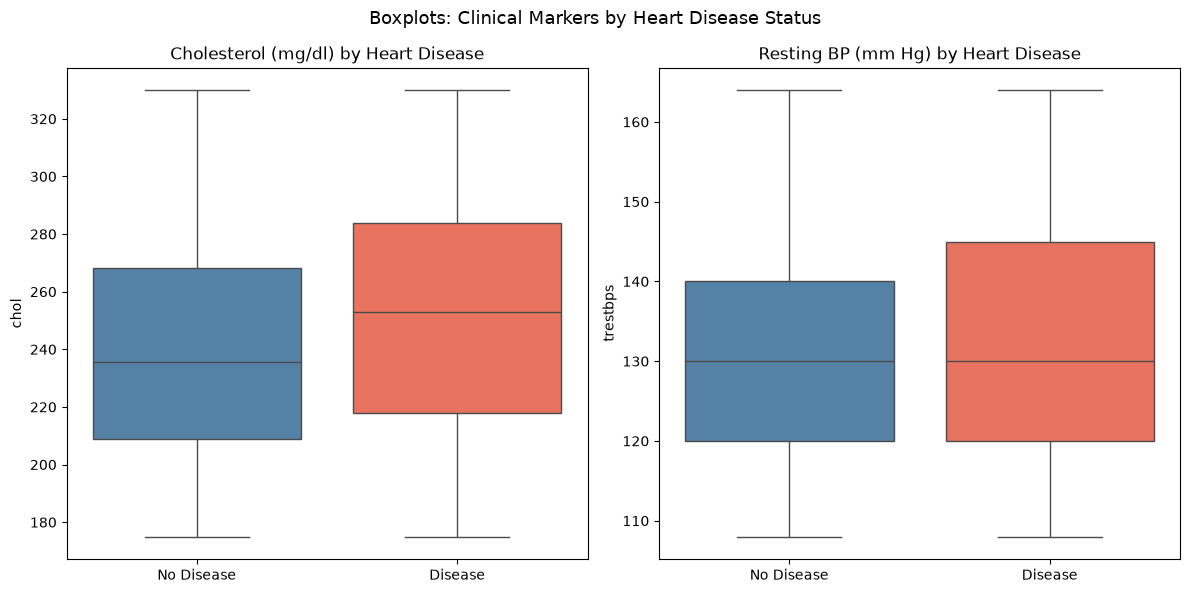

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, col, title in zip(axes, ['chol', 'trestbps'], ['Cholesterol (mg/dl)', 'Resting BP (mm Hg)']):
    sns.boxplot(x='target', y=col, data=df, palette=['steelblue', 'tomato'], ax=ax)
    ax.set_xticklabels(['No Disease', 'Disease'])
    ax.set_title(f'{title} by Heart Disease')
    ax.set_xlabel('')
plt.suptitle('Boxplots: Clinical Markers by Heart Disease Status', fontsize=13)
plt.tight_layout()
plt.savefig('viz3_boxplots.png', dpi=150)
plt.show()

Cell 9 — Visualization 4: Pairplot

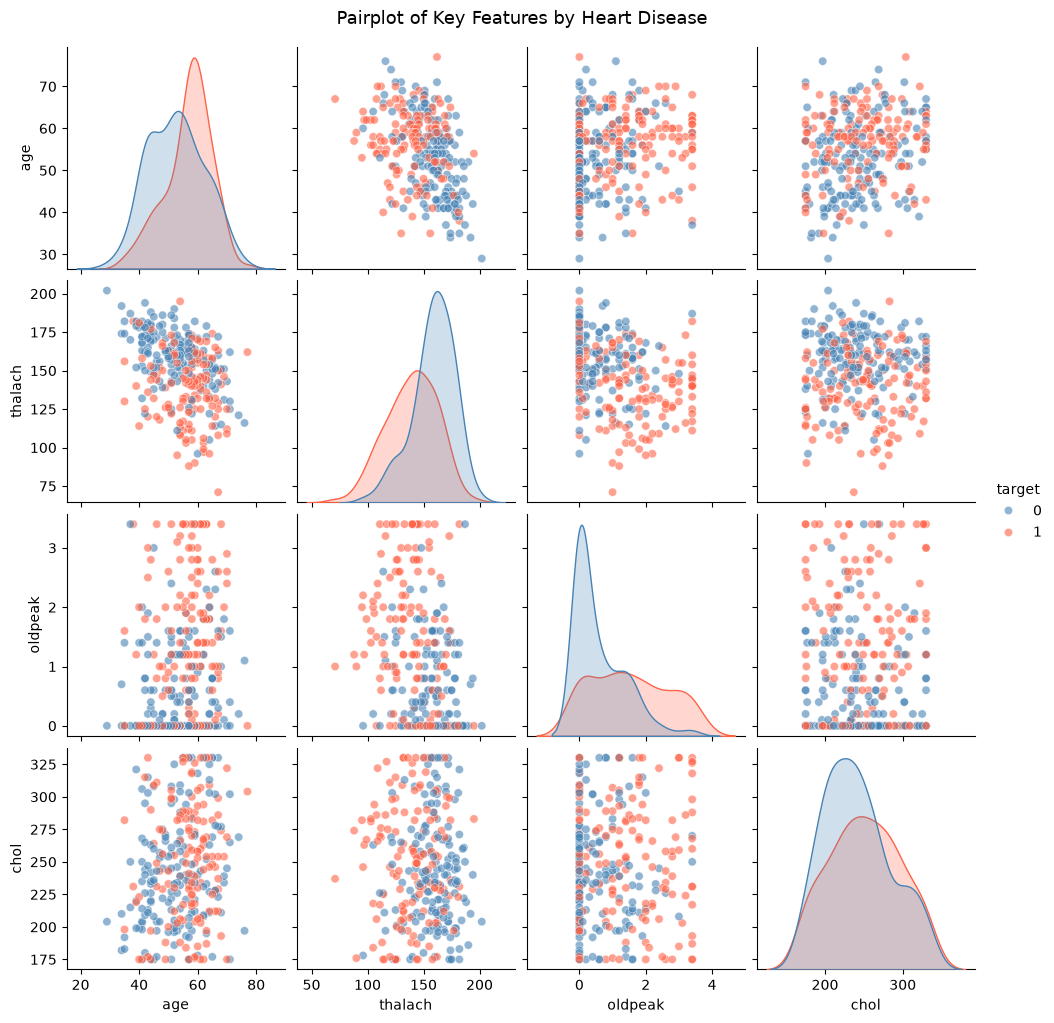

In [16]:
key_features = ['age', 'thalach', 'oldpeak', 'chol', 'target']
sns.pairplot(df[key_features], hue='target', palette={0: 'steelblue', 1: 'tomato'},
             plot_kws={'alpha': 0.6}, diag_kind='kde')
plt.suptitle('Pairplot of Key Features by Heart Disease', y=1.02, fontsize=13)
plt.savefig('viz4_pairplot.png', dpi=150)
plt.show()

Cell 10 — Visualization 5: Class Distribution & Chest Pain

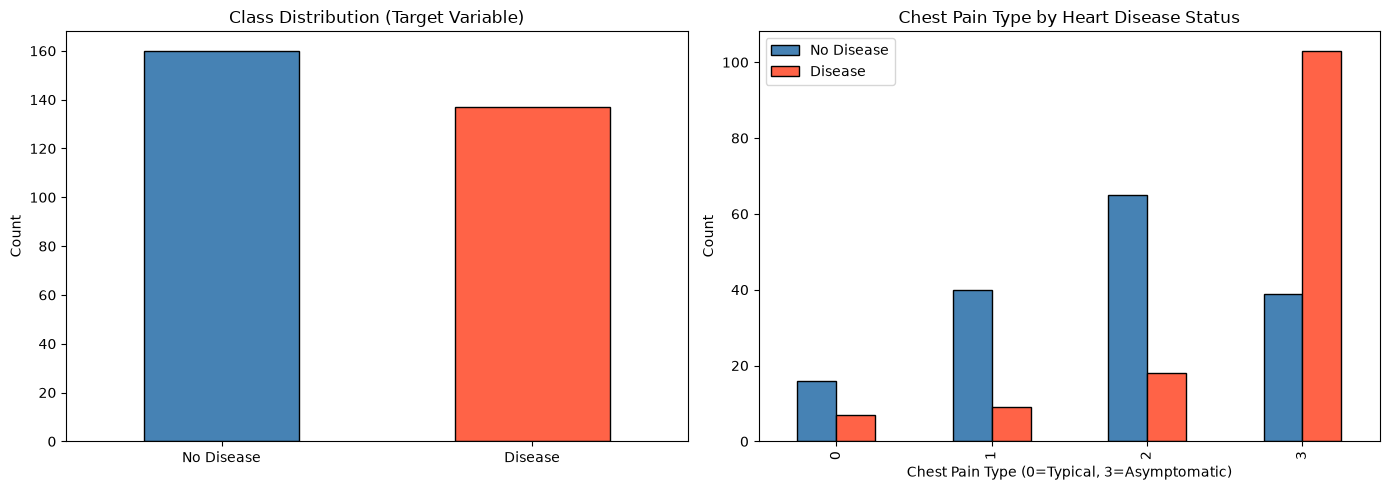

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df['target'].value_counts().rename({0: 'No Disease', 1: 'Disease'}).plot(
    kind='bar', ax=axes[0], color=['steelblue', 'tomato'], edgecolor='black')
axes[0].set_title('Class Distribution (Target Variable)')
axes[0].set_xlabel(''); axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['No Disease', 'Disease'], rotation=0)
cp_target = df.groupby(['cp', 'target']).size().unstack()
cp_target.plot(kind='bar', ax=axes[1], color=['steelblue', 'tomato'], edgecolor='black')
axes[1].set_title('Chest Pain Type by Heart Disease Status')
axes[1].set_xlabel('Chest Pain Type (0=Typical, 3=Asymptomatic)')
axes[1].set_ylabel('Count')
axes[1].legend(['No Disease', 'Disease'])
plt.tight_layout()
plt.savefig('viz5_class_and_cp.png', dpi=150)
plt.show()

Cell 11 — Build and Train:

In [18]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(13,)),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer=keras.optimizers.Adam(0.001),
              loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

early_stop = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True, monitor='val_loss')
lr_reduce = keras.callbacks.ReduceLROnPlateau(patience=7, factor=0.5, verbose=1)

history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_data=(X_val, y_val),
                    callbacks=[early_stop, lr_reduce], verbose=1)

I0000 00:00:1791741952.757544  440689 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791741952.796660  440689 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791741954.007822  440689 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1791741955.055805  440689 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure th

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,521 (13.75 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.5314 - loss: 0.7184 - val_accuracy: 0.4000 - val_loss: 0.7331 - learning_rate: 0.0010
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5459 - loss: 0.6845 - val_accuracy: 0.5333 - val_loss: 0.6894 - learning_rate: 0.0010
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6570 - loss: 0.6500 - val_accuracy: 0.6222 - val_loss: 0.6541 - learning_rate: 0.0010
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6184 - loss: 0.6344 - val_accuracy: 0.6667 - val_loss: 0.6286 - learning_rate: 0.0010
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7488 - loss: 0.5779 - val_accuracy: 0.7333 - val_loss: 0.6058 - learning_rate: 0.0010
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7488 - loss: 0.5681 - val_accuracy: 0.7333 - val_loss: 0.5835 - learning_rate: 0.0010
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7246 - loss: 0.5472 - val_accuracy: 0.

Cell 12 — Visualization 6: Loss Curve

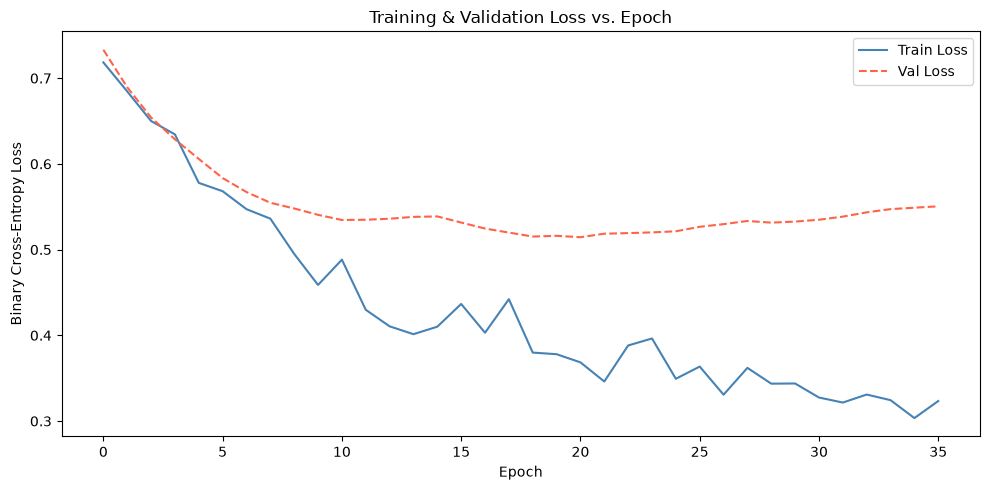

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history.history['loss'], label='Train Loss', color='steelblue')
ax.plot(history.history['val_loss'], label='Val Loss', color='tomato', linestyle='--')
ax.set_title('Training & Validation Loss vs. Epoch')
ax.set_xlabel('Epoch'); ax.set_ylabel('Binary Cross-Entropy Loss')
ax.legend()
plt.tight_layout()
plt.savefig('viz6_loss_curve.png', dpi=150)
plt.show()

Cell 13 — Visualization 7: Accuracy Curve

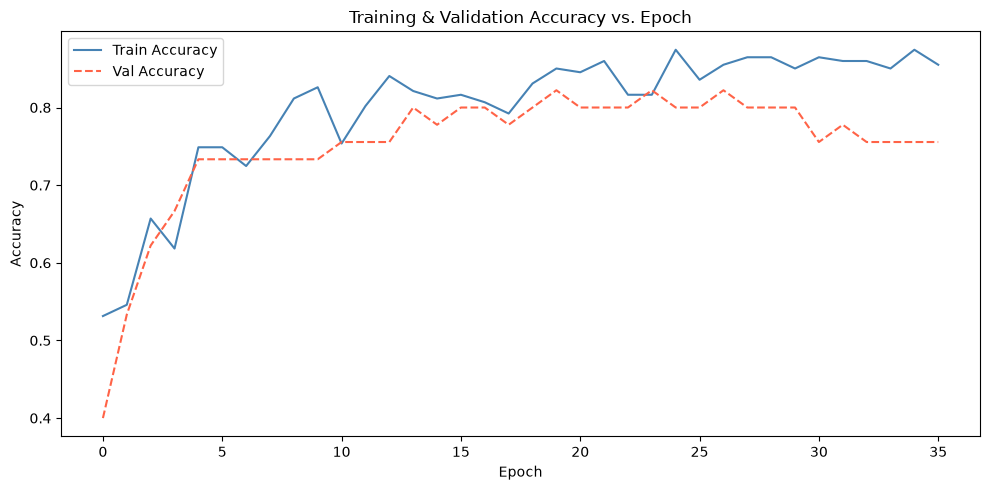

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history.history['accuracy'], label='Train Accuracy', color='steelblue')
ax.plot(history.history['val_accuracy'], label='Val Accuracy', color='tomato', linestyle='--')
ax.set_title('Training & Validation Accuracy vs. Epoch')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy')
ax.legend()
plt.tight_layout()
plt.savefig('viz7_accuracy_curve.png', dpi=150)
plt.show()

Cell 14 — Visualization 8: Confusion Matrix

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


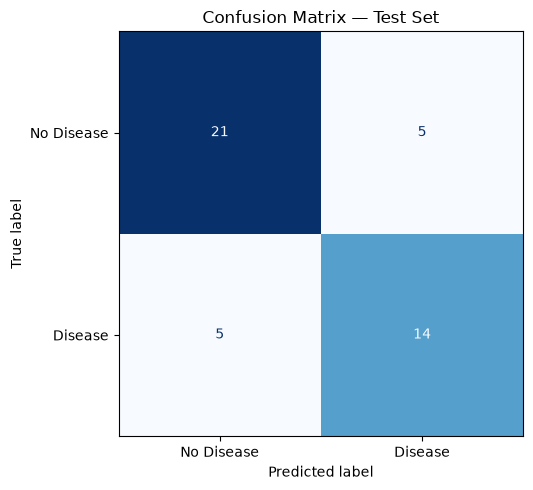


Classification Report:
              precision    recall  f1-score   support

  No Disease       0.81      0.81      0.81        26
     Disease       0.74      0.74      0.74        19

    accuracy                           0.78        45
   macro avg       0.77      0.77      0.77        45
weighted avg       0.78      0.78      0.78        45



In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_pred = (model.predict(X_test) > 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No Disease', 'Disease'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix — Test Set')
plt.tight_layout()
plt.savefig('viz8_confusion_matrix.png', dpi=150)
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Disease', 'Disease']))

Cell 15 — Visualization 9: ROC Curve

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


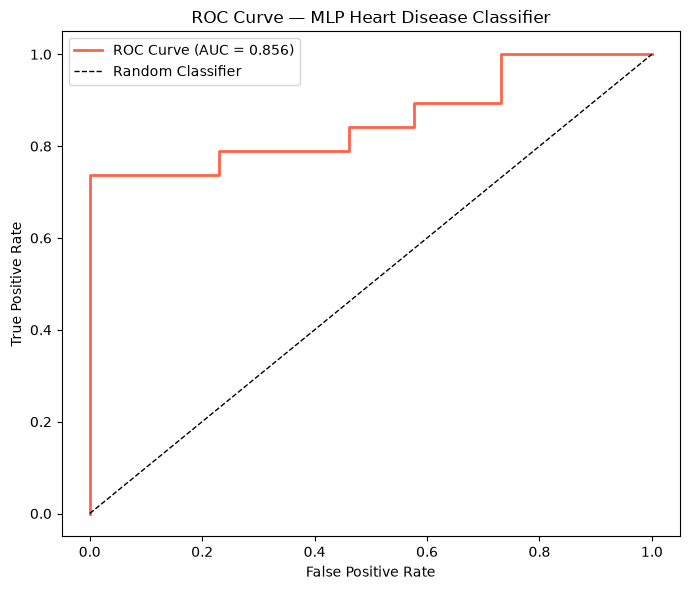

Test AUC Score: 0.8563


In [22]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = model.predict(X_test).ravel()
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='tomato', lw=2, label=f'ROC Curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — MLP Heart Disease Classifier')
plt.legend()
plt.tight_layout()
plt.savefig('viz9_roc_curve.png', dpi=150)
plt.show()

print(f"Test AUC Score: {auc:.4f}")